# Practical 1, Part 2: My first neural network

This notebook trains a **multilayer perceptron (MLP) written from scratch** to classify the handwritten digits of the scikit-learn **Digits** dataset (1,797 images of 8 × 8 pixels, 10 classes).

- The network, the loss and the training loop are written by hand with `autograd.numpy`.
- The only automatic part is the gradient: `autograd` differentiates the loss with respect to the network parameters.
- No deep learning framework is used; scikit-learn is used only to load the data and split it.

The design is documented in `spec.md` (what), `architecture.md` (how) and `tasks.md` (in what order); decisions are recorded in `log.md`.

**How to run.** Install the dependencies once (`pip install numpy autograd scikit-learn matplotlib jupyter`), then choose **Restart kernel and run all**. Every code cell ends with `assert` checks: if a requirement is broken, the run stops with a message.

**Sections**

0. Setup
1. Data
2. Model
3. Loss and gradients
4. Training
5. Evaluation and visualization
6. Robustness

## 0. Setup

### Imports

Two NumPy modules are imported on purpose:

- `autograd.numpy` as `anp`: a thin wrapper around NumPy that `autograd` can trace. **Every function the gradient flows through (forward pass, softmax, loss) uses `anp`.**
- `numpy` as `np`: plain NumPy, for code that is never differentiated (data preparation, random numbers, metrics, checks).

`value_and_grad` returns, in one call, the value of a function and its gradient. scikit-learn only provides the dataset (`load_digits`) and the stratified split (`train_test_split`).

In [1]:
from importlib.metadata import version

import autograd.numpy as anp
import numpy as np
import matplotlib.pyplot as plt
from autograd import value_and_grad
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

for package in ["numpy", "autograd", "scikit-learn", "matplotlib"]:
    print(f"{package:<13} {version(package)}")

numpy         2.5.3
autograd      1.9.1
scikit-learn  1.9.1
matplotlib    3.11.2


### Configuration

Every setting lives in one dictionary, `CONFIG`, so no value is hard-coded inside the functions. The values and the reasons for them are in `architecture.md` §6:

| Key | Value | Meaning |
| --- | --- | --- |
| `seed` | 0 | Seed for the split and the weight initialization (shuffling uses `seed + 1`) |
| `test_size` | 0.2 | Fraction of the images kept for the test set |
| `layer_sizes` | [64, 64, 10] | 64 input pixels → 64 hidden ReLU units → 10 output classes |
| `learning_rate` | 0.1 | Step size η in the update θ ← θ − η · ∂L/∂θ |
| `batch_size` | 32 | Number of images per mini-batch |
| `epochs` | 30 | Number of full passes over the training set |

`validate_config` checks the training hyperparameters before they are used and raises a `ValueError` with a clear message if one is invalid (`spec.md` FR7). The layer sizes are checked later, by `init_params` (task 2.1).

In [2]:
CONFIG = {
    "seed": 0,
    "test_size": 0.2,
    "layer_sizes": [64, 64, 10],
    "learning_rate": 0.1,
    "batch_size": 32,
    "epochs": 30,
}


def validate_config(config):
    """Check that the training hyperparameters in `config` are usable.

    Parameters
    ----------
    config : dict
        Must contain the keys of CONFIG.

    Returns
    -------
    None. Raises ValueError with a clear message if a key is missing
    or a value is out of range.
    """
    required = ["seed", "test_size", "layer_sizes", "learning_rate", "batch_size", "epochs"]
    missing = [key for key in required if key not in config]
    if missing:
        raise ValueError(f"Configuration is missing the keys {missing}.")

    if not 0 < config["test_size"] < 1:
        raise ValueError(f"Test fraction must be between 0 and 1 (exclusive), got {config['test_size']}.")
    if config["learning_rate"] <= 0:
        raise ValueError(f"Learning rate must be > 0, got {config['learning_rate']}.")
    # Batch size and epochs are counts, so they must be whole numbers, not just positive.
    for key, name in [("batch_size", "Batch size"), ("epochs", "Number of epochs")]:
        value = config[key]
        if not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be an integer >= 1, got {value!r}.")


validate_config(CONFIG)
for key, value in CONFIG.items():
    print(f"{key:<14} {value}")

# Check (task 0.1): the configuration is complete and valid.
assert set(CONFIG) == {"seed", "test_size", "layer_sizes", "learning_rate", "batch_size", "epochs"}, "CONFIG has unexpected keys"
print("\nConfiguration is valid.")

seed           0
test_size      0.2
layer_sizes    [64, 64, 10]
learning_rate  0.1
batch_size     32
epochs         30

Configuration is valid.


## 1. Data

Load the Digits dataset, split it into train and test sets, standardize the pixels and convert the labels to one-hot vectors (`spec.md` FR1).

### Load and split

`load_digits` returns 1,797 images, each flattened into a row of 64 pixel values (integers 0–16), and their labels (0–9). `load_data` converts the pixels to `float64` and the labels to integers.

The data are then split into **80 % train / 20 % test**:

- **Stratified** (`stratify=y`): each class keeps the same proportion in both sets, so the test accuracy is not biased by a set that happens to have, e.g., few 8s.
- **Fixed seed** (`random_state=CONFIG["seed"]`): the split is the same on every run.
- The sets are called `X_train_raw` and `X_test_raw` because they are not standardized yet (next task). The raw test images are kept for the prediction grid in section 5, where pixels must be shown on their original 0–16 scale.

The test set is put aside here and is **never** used to fit anything: not the standardization, not the parameters.

In [3]:
def load_data():
    """Load the scikit-learn Digits dataset.

    Returns
    -------
    X : ndarray, shape (1797, 64), float64
        One flattened 8x8 image per row, pixel values 0-16.
    y : ndarray, shape (1797,), int64
        The digit shown in each image, 0-9.
    """
    digits = load_digits()
    X = digits.data.astype(np.float64)
    y = digits.target.astype(np.int64)
    return X, y


X, y = load_data()
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=CONFIG["test_size"],
    stratify=y,                       # same class proportions in train and test
    random_state=CONFIG["seed"],      # reproducible split
)

print(f"X {X.shape}, y {y.shape}, pixel range {X.min():.0f}-{X.max():.0f}")
print(f"Train: X {X_train_raw.shape}, y {y_train.shape}")
print(f"Test:  X {X_test_raw.shape}, y {y_test.shape}\n")

# Class proportions in each set: they should be almost identical (stratified split).
train_share = np.bincount(y_train, minlength=10) / len(y_train)
test_share = np.bincount(y_test, minlength=10) / len(y_test)
print("Class   All  Train %  Test %")
for k in range(10):
    print(f"{k:>5} {np.sum(y == k):>5} {100 * train_share[k]:>8.2f} {100 * test_share[k]:>7.2f}")

# Check (task 1.1)
assert X.shape == (1797, 64) and y.shape == (1797,), "Unexpected dataset shape"
assert X.min() == 0 and X.max() == 16, "Pixel values should range from 0 to 16"
assert X_train_raw.shape == (1437, 64) and X_test_raw.shape == (360, 64), "Unexpected split sizes"
assert len(y_train) == 1437 and len(y_test) == 360, "Labels do not match the split sizes"
assert np.max(np.abs(train_share - test_share)) < 0.01, "Class proportions differ by 1 percentage point or more"
print("\nData loaded and split correctly.")

X (1797, 64), y (1797,), pixel range 0-16
Train: X (1437, 64), y (1437,)
Test:  X (360, 64), y (360,)

Class   All  Train %  Test %
    0   178     9.88   10.00
    1   182    10.16   10.00
    2   177     9.88    9.72
    3   183    10.16   10.28
    4   181    10.09   10.00
    5   182    10.09   10.28
    6   181    10.09   10.00
    7   179     9.95   10.00
    8   174     9.67    9.72
    9   180    10.02   10.00

Data loaded and split correctly.


### Standardize the pixels

Each of the 64 pixel features is standardized: $x' = (x - \mu) / \sigma$, where $\mu$ and $\sigma$ are that pixel's mean and standard deviation.

- **Why:** features on a common scale (mean 0, std 1) make the loss surface better conditioned, so one learning rate suits all the weights and SGD converges faster. Raw pixels (0–16) would give large, uneven inputs to the first layer.
- **Fitted on the training set only.** `fit_standardizer` computes $\mu$ and $\sigma$ from `X_train_raw`; `apply_standardizer` then uses those **same** values on both sets. Computing them on the test set (or on all the data) would leak test information into training.
- **Constant pixels.** Some border pixels are 0 in every training image, so their $\sigma$ is 0 and the division would give `NaN`. Their $\sigma$ is replaced by 1: the standardized value is then $0 - 0 = 0$, which is correct (the feature carries no information).

In [4]:
def fit_standardizer(X_train):
    """Compute the per-feature statistics used for standardization.

    Parameters
    ----------
    X_train : ndarray, shape (N, D)
        Training inputs only (never the test set, to avoid data leakage).

    Returns
    -------
    mean : ndarray, shape (D,)
    std : ndarray, shape (D,)
        Standard deviation per feature, with 0 replaced by 1 so that
        constant features can be divided safely.
    """
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std = np.where(std == 0, 1.0, std)
    return mean, std


def apply_standardizer(X, mean, std):
    """Standardize X with statistics computed by fit_standardizer.

    Parameters
    ----------
    X : ndarray, shape (N, D)
    mean, std : ndarray, shape (D,)

    Returns
    -------
    ndarray, shape (N, D): (X - mean) / std, broadcast over the rows.
    """
    return (X - mean) / std


mean, std = fit_standardizer(X_train_raw)
X_train = apply_standardizer(X_train_raw, mean, std)
X_test = apply_standardizer(X_test_raw, mean, std)

constant = X_train_raw.std(axis=0) == 0
varying = ~constant
print(f"Constant features in the training set (std 0 -> 1): {constant.sum()} -> pixels {np.flatnonzero(constant).tolist()}")
print(f"Train, non-constant features: max |mean| = {np.abs(X_train[:, varying].mean(axis=0)).max():.2e}, "
      f"std range = {X_train[:, varying].std(axis=0).min():.6f}-{X_train[:, varying].std(axis=0).max():.6f}")
print(f"Test (uses the train statistics, so only approximately 0 / 1): "
      f"mean of feature means = {X_test.mean():.3f}, mean of feature stds = {X_test[:, varying].std(axis=0).mean():.3f}")

# Check (task 1.2)
assert np.all(np.abs(X_train[:, varying].mean(axis=0)) < 1e-6), "Training features are not centred"
assert np.all(np.abs(X_train[:, varying].std(axis=0) - 1) < 1e-6), "Training features do not have std 1"
assert np.all(X_train[:, constant] == 0), "Constant training features should be 0 after standardization"
assert np.all(np.isfinite(X_train)) and np.all(np.isfinite(X_test)), "NaN or Inf after standardization"
assert X_train.shape == (1437, 64) and X_test.shape == (360, 64), "Standardization changed the shapes"
print("\nStandardization correct (statistics from the training set only).")

Constant features in the training set (std 0 -> 1): 4 -> pixels [0, 24, 32, 39]
Train, non-constant features: max |mean| = 1.99e-16, std range = 1.000000-1.000000
Test (uses the train statistics, so only approximately 0 / 1): mean of feature means = -0.001, mean of feature stds = 0.966

Standardization correct (statistics from the training set only).


### One-hot labels

The network outputs 10 probabilities per image, so each label is converted into a **one-hot** vector of length 10: a 1 in the position of the true class and 0 elsewhere (e.g. `3 → [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`). This is the target distribution $Y$ that the cross-entropy loss (section 3) compares with the predicted probabilities.

`one_hot` builds it by indexing the identity matrix: row $k$ of `np.eye(10)` is exactly the one-hot vector of class $k$.

Before converting, it **validates the labels** (`spec.md` FR7): every label must be a whole number in 0–9. Without this check, a label of 12 would raise a cryptic `IndexError`, and a label of −1 would silently become class 9 (negative indices wrap around in NumPy).

In [5]:
def one_hot(y, num_classes=10):
    """Convert integer class labels to one-hot vectors.

    Parameters
    ----------
    y : array-like, shape (N,)
        Class labels; each must be a whole number in 0..num_classes-1.
    num_classes : int

    Returns
    -------
    Y : ndarray, shape (N, num_classes), float64
        Y[i, k] = 1 if y[i] == k, else 0.

    Raises ValueError if a label is not a whole number or is out of range.
    """
    y = np.asarray(y)
    if y.ndim != 1:
        raise ValueError(f"Labels must be a 1-D array, got shape {y.shape}.")
    for i, label in enumerate(y):
        if label != np.round(label):
            raise ValueError(f"Label {label} at index {i} is not an integer; labels must be integers in 0-{num_classes - 1}.")
        if not 0 <= label < num_classes:
            raise ValueError(f"Label {label} at index {i} is out of range; labels must be integers in 0-{num_classes - 1}.")
    return np.eye(num_classes)[y.astype(np.int64)]


Y_train = one_hot(y_train)
Y_test = one_hot(y_test)

print(f"Y_train {Y_train.shape}, Y_test {Y_test.shape}\n")
print("First 3 training labels and their one-hot vectors:")
for label, row in zip(y_train[:3], Y_train[:3]):
    print(f"  {label} -> {row.astype(int)}")

# Check (task 1.3)
assert Y_train.shape == (1437, 10) and Y_test.shape == (360, 10), "Unexpected one-hot shapes"
assert np.array_equal(Y_train.argmax(axis=1), y_train) and np.array_equal(Y_test.argmax(axis=1), y_test), "argmax(Y) does not recover the labels"
assert np.all(Y_train.sum(axis=1) == 1) and np.all(Y_test.sum(axis=1) == 1), "A one-hot row does not sum to 1"
assert set(np.unique(Y_train)) == {0.0, 1.0}, "One-hot entries must be 0 or 1"
print("\nOne-hot labels correct.")

Y_train (1437, 10), Y_test (360, 10)

First 3 training labels and their one-hot vectors:
  3 -> [0 0 0 1 0 0 0 0 0 0]
  9 -> [0 0 0 0 0 0 0 0 0 1]
  1 -> [0 1 0 0 0 0 0 0 0 0]

One-hot labels correct.


## 2. Model

Create the network parameters and write the forward pass: hidden layer with ReLU, then a 10-class softmax (`spec.md` FR2).

### Parameters

The network is described by its list of layer sizes, `CONFIG["layer_sizes"] = [64, 64, 10]`: 64 input pixels → 64 hidden units → 10 output classes. Each pair of consecutive sizes defines one layer with a weight matrix and a bias vector.

**Representation.** The parameters are a list with one `(W, b)` tuple per layer:

```python
params = [(W1, b1), (W2, b2)]   # W1 (64, 64), b1 (64,), W2 (64, 10), b2 (10,)
```

`autograd` can differentiate with respect to such a nested list and returns the gradient with **the same structure**, so `grads[0][0]` will be ∂L/∂W1.

**Shapes.** One image per row: a layer computes `Z = A @ W + b` with `A` of shape (B, n_in), so `W` must be (n_in, n_out) and `b` (n_out,). Total: 64·64 + 64 + 64·10 + 10 = **4,810** parameters.

**Initialization.**

- Weights: random normal with mean 0 and variance 2 / n_in (**He initialization**). ReLU sets about half of its inputs to 0, which halves the signal's variance; the factor 2 compensates, so activations keep roughly the same scale from layer to layer and the gradients neither vanish nor explode at the start.
- Biases: 0. The random weights already make the units different from each other (breaking the symmetry), so the biases don't need to be random.
- The random generator is created from `CONFIG["seed"]`, so the initial weights are the same on every run.

**Checks** (`spec.md` FR7). `init_params` rejects invalid layer sizes. `check_params` verifies that the shapes chain correctly (first layer matches the number of input features, each layer's input matches the previous layer's output, each bias matches its weight). The forward pass (next task) will call it before computing, so a shape mistake gives a clear message instead of a cryptic matrix-multiplication error.

In [6]:
def init_params(layer_sizes, rng):
    """Create the weights and biases of an MLP.

    Parameters
    ----------
    layer_sizes : list of int
        [n_input, n_hidden_1, ..., n_output], at least 2 positive integers.
    rng : numpy.random.Generator
        Source of randomness (seeded, for reproducibility).

    Returns
    -------
    params : list of (W, b) tuples, one per layer
        W has shape (n_in, n_out), drawn from N(0, 2 / n_in) (He initialization);
        b has shape (n_out,), all zeros.

    Raises ValueError if layer_sizes is not a list of at least 2 positive integers.
    """
    valid = (len(layer_sizes) >= 2
             and all(isinstance(n, (int, np.integer)) and n >= 1 for n in layer_sizes))
    if not valid:
        raise ValueError(f"Layer sizes must be at least [input, output] with positive integers, got {list(layer_sizes)}.")

    params = []
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        W = rng.normal(loc=0.0, scale=np.sqrt(2.0 / n_in), size=(n_in, n_out))
        b = np.zeros(n_out)
        params.append((W, b))
    return params


def check_params(params, n_features):
    """Check that the parameter shapes chain correctly for inputs with n_features columns.

    Parameters
    ----------
    params : list of (W, b) tuples
    n_features : int
        Number of columns of the input X.

    Returns
    -------
    None. Raises ValueError with a clear message on the first mismatch.
    """
    expected_inputs = n_features
    for layer, (W, b) in enumerate(params, start=1):
        if len(W.shape) != 2 or len(b.shape) != 1:
            raise ValueError(f"Layer {layer}: weight must be 2-D and bias 1-D, got shapes {W.shape} and {b.shape}.")
        if W.shape[0] != expected_inputs:
            if layer == 1:
                raise ValueError(f"Input has {n_features} features, but the first layer expects {W.shape[0]}.")
            raise ValueError(f"Layer {layer} weight has {W.shape[0]} input rows, "
                             f"but layer {layer - 1} outputs {expected_inputs} values.")
        if b.shape[0] != W.shape[1]:
            raise ValueError(f"Layer {layer} bias has {b.shape[0]} values, but its weight has {W.shape[1]} outputs.")
        expected_inputs = W.shape[1]


params = init_params(CONFIG["layer_sizes"], np.random.default_rng(CONFIG["seed"]))
check_params(params, X_train.shape[1])

n_params = 0
for layer, (W, b) in enumerate(params, start=1):
    target_std = np.sqrt(2.0 / W.shape[0])
    print(f"Layer {layer}: W {W.shape}, b {b.shape}, std(W) = {W.std():.4f} (target {target_std:.4f})")
    n_params += W.size + b.size
print(f"Total parameters: {n_params:,}")

# Check (task 2.1)
assert [(W.shape, b.shape) for W, b in params] == [((64, 64), (64,)), ((64, 10), (10,))], "Unexpected parameter shapes"
assert n_params == 4810, "The 64 -> 64 -> 10 network should have 4,810 parameters"
assert all(np.all(b == 0) for _, b in params), "Biases should start at 0"
assert all(abs(W.std() / np.sqrt(2.0 / W.shape[0]) - 1) < 0.10 for W, _ in params), "Weight std is not within 10% of sqrt(2 / n_in)"
print("\nParameters initialized correctly.")

Layer 1: W (64, 64), b (64,), std(W) = 0.1763 (target 0.1768)
Layer 2: W (64, 10), b (10,), std(W) = 0.1755 (target 0.1768)
Total parameters: 4,810

Parameters initialized correctly.


### Forward pass

The forward pass turns a batch of images `X` (B, 64) into class probabilities (B, 10):

$$H = \mathrm{ReLU}(X W_1 + b_1) \quad (B, 64), \qquad Z = H W_2 + b_2 \quad (B, 10), \qquad P = \mathrm{softmax}(Z) \quad (B, 10)$$

- **ReLU**, $\max(z, 0)$, is the nonlinearity. Without it, two affine layers would collapse into a single affine map, and the network could only draw linear boundaries between classes.
- `forward` returns the **logits** $Z$ (unnormalized scores), not probabilities. The loss (section 3) works on the logits directly because that is numerically safer.
- **Softmax** turns logits into probabilities: $p_k = e^{z_k} / \sum_j e^{z_j}$. Computed naively, $e^{1000}$ overflows to `inf` and the result becomes `NaN`. `log_softmax` uses the identity $\log p_k = z_k - m - \log \sum_j e^{z_j - m}$ with $m = \max_j z_j$: subtracting the row maximum doesn't change the result but makes every exponent ≤ 0, so nothing overflows.
- These functions use **`anp`** (`autograd.numpy`) so that `autograd` can differentiate through them in section 3.

`predict` takes the class with the largest logit (the same as the largest probability, since softmax preserves order) and `accuracy` is the fraction of correct predictions.

In [7]:
def relu(Z):
    """ReLU activation, element-wise max(Z, 0). Same shape as Z."""
    return anp.maximum(Z, 0)


def log_softmax(Z):
    """Numerically stable log of the softmax, row by row.

    Parameters
    ----------
    Z : array, shape (B, K), logits

    Returns
    -------
    array, shape (B, K): log p[i, k] = Z[i, k] - log(sum_j exp(Z[i, j])).
    """
    m = anp.max(Z, axis=1, keepdims=True)   # (B, 1); subtracting it keeps exp() from overflowing
    return Z - m - anp.log(anp.sum(anp.exp(Z - m), axis=1, keepdims=True))


def forward(params, X):
    """Compute the logits of the MLP.

    Parameters
    ----------
    params : list of (W, b) tuples (see init_params)
    X : array, shape (B, n_features)

    Returns
    -------
    Z : array, shape (B, n_classes). Hidden layers apply affine + ReLU;
        the last layer is affine only (softmax is applied by the caller).
    """
    check_params(params, X.shape[1])
    A = X
    for W, b in params[:-1]:
        A = relu(anp.dot(A, W) + b)        # (B, n_in) @ (n_in, n_out) + (n_out,) -> (B, n_out)
    W_out, b_out = params[-1]
    return anp.dot(A, W_out) + b_out


def predict_proba(params, X):
    """Class probabilities, shape (B, n_classes); each row sums to 1."""
    return anp.exp(log_softmax(forward(params, X)))


def predict(params, X):
    """Predicted class of each row (index of the largest logit), shape (B,)."""
    return np.argmax(forward(params, X), axis=1)


def accuracy(params, X, y):
    """Fraction of rows of X whose predicted class equals the integer label in y."""
    return np.mean(predict(params, X) == y)


# 1) Probabilities for 5 training images.
probs = predict_proba(params, X_train[:5])
print(f"Probabilities: shape {probs.shape}, min {probs.min():.4f}, max {probs.max():.4f}")
print(f"Row sums: {np.round(probs.sum(axis=1), 6)}")

# 2) Very large logits: the naive formula overflows, log_softmax does not.
Z_large = np.array([[1000.0, 0.0, -1000.0], [1000.0, 1000.0, 999.0]])
with np.errstate(over="ignore", invalid="ignore"):   # the overflow is the point of this demonstration
    naive = np.exp(Z_large) / np.exp(Z_large).sum(axis=1, keepdims=True)
stable = np.exp(log_softmax(Z_large))
print(f"\nLogits of size 1000 -> naive softmax: {naive.tolist()}")
print(f"                    -> log_softmax:   {np.round(stable, 4).tolist()}")

# 3) The untrained network should be close to random guessing (10 % for 10 classes).
untrained_acc = accuracy(params, X_train, y_train)
print(f"\nUntrained accuracy on the training set: {100 * untrained_acc:.1f} %")

# Check (task 2.2)
assert probs.shape == (5, 10), "Probabilities should have shape (5, 10)"
assert np.all((probs >= 0) & (probs <= 1)), "Probabilities must lie in [0, 1]"
assert np.allclose(probs.sum(axis=1), 1, atol=1e-6), "Probability rows must sum to 1"
assert np.all(np.isfinite(stable)) and np.allclose(stable.sum(axis=1), 1, atol=1e-6), "log_softmax is not stable for large logits"
assert np.array_equal(predict(params, X_train[:5]), probs.argmax(axis=1)), "predict disagrees with the probabilities"
assert 0 <= untrained_acc <= 0.30, "The untrained network should be near chance level"
print("\nForward pass correct.")

Probabilities: shape (5, 10), min 0.0027, max 0.3481
Row sums: [1. 1. 1. 1. 1.]

Logits of size 1000 -> naive softmax: [[nan, 0.0, 0.0], [nan, nan, nan]]
                    -> log_softmax:   [[1.0, 0.0, 0.0], [0.4223, 0.4223, 0.1554]]

Untrained accuracy on the training set: 14.3 %

Forward pass correct.


## 3. Loss and gradients

Write the cross-entropy loss with `autograd.numpy`, get its gradient with respect to the parameters with `autograd`, and check it against finite differences (`spec.md` FR3, FR4).

### Cross-entropy loss

For a batch of $B$ images with one-hot targets $Y$ and predicted probabilities $P$, the **mean cross-entropy** is

$$L = -\frac{1}{B}\sum_{i=1}^{B}\sum_{k=1}^{10} Y_{ik}\,\log P_{ik}.$$

Because each row of $Y$ has a single 1, the inner sum keeps only $-\log P_{i,y_i}$, the negative log-probability given to the **true** class. So $L$ is 0 when the network puts probability 1 on every correct class, and grows without bound as that probability goes to 0. It is the negative log-likelihood of the labels under the model, which is why minimizing it fits the data.

**Implementation choices:**

- It is computed from `log_softmax(forward(...))`, never as `log(predict_proba(...))`: a probability that underflows to 0 would give `log(0) = -inf`. With log-softmax, a very wrong prediction gives a large but finite loss.
- It is written only with `anp`, so `autograd` can differentiate it (task 3.2).
- Its first argument is `params`: the loss is seen as a function of the parameters, with the data `X`, `Y` held fixed. This is the function that training minimizes.

**Reference values used in the checks:**

- If every logit is equal, every class gets $P = 1/10$, so $L = -\log(1/10) = \ln 10 \approx 2.3026$. All-zero parameters produce exactly this.
- If the network is confident and right, $L \approx 0$.
- If it is confident and wrong (logit 100 on a wrong class), $L \approx 100$: large, but finite.

In [8]:
def cross_entropy(params, X, Y):
    """Mean cross-entropy between the network's predictions and one-hot targets.

    Parameters
    ----------
    params : list of (W, b) tuples
    X : array, shape (B, n_features)
    Y : array, shape (B, n_classes), one-hot

    Returns
    -------
    Scalar: -(1/B) * sum_i sum_k Y[i, k] * log p[i, k]. Written with anp only,
    so autograd can differentiate it with respect to params.
    """
    log_probs = log_softmax(forward(params, X))          # (B, n_classes)
    return -anp.mean(anp.sum(Y * log_probs, axis=1))      # sum over classes, mean over the batch


# 1) Uniform predictions: all-zero parameters give equal logits -> L = ln 10.
zero_params = [(np.zeros_like(W), np.zeros_like(b)) for W, b in params]
loss_uniform = cross_entropy(zero_params, X_train, Y_train)

# 2) Confident and correct: a 1-layer "network" whose input is the one-hot target itself,
#    with W = 100 * identity, so the logit of the true class is 100 and all others 0.
confident_params = [(100 * np.eye(10), np.zeros(10))]
loss_confident = cross_entropy(confident_params, Y_train[:5], Y_train[:5])

# 3) Confident and wrong: same network, but the true labels are shifted by one class,
#    so the true class gets logit 0 and a wrong class gets 100. The loss is large but finite
#    (a naive log(probability) would give log(0) = -inf here).
loss_wrong = cross_entropy(confident_params, Y_train[:5], np.roll(Y_train[:5], 1, axis=1))

# 4) The untrained network from task 2.1.
loss_untrained = cross_entropy(params, X_train, Y_train)

print(f"Uniform predictions:     L = {loss_uniform:.6f}   (ln 10 = {np.log(10):.6f})")
print(f"Confident and correct:   L = {loss_confident + 0.0:.2e}")   # + 0.0 turns -0.0 into 0.0 for display
print(f"Confident and wrong:     L = {loss_wrong:.2f}")
print(f"Untrained network:       L = {loss_untrained:.4f}")

# Check (task 3.1)
assert abs(loss_uniform - np.log(10)) < 1e-9, "Uniform predictions should give ln 10"
assert loss_confident < 1e-6, "Confident correct predictions should give a loss near 0"
assert np.isfinite(loss_wrong) and loss_wrong > 50, "Confident wrong predictions should give a large but finite loss"
assert np.isfinite(loss_untrained) and 1 < loss_untrained < 5, "Untrained loss should be finite and of the order of ln 10"
print("\nCross-entropy correct.")

Uniform predictions:     L = 2.302585   (ln 10 = 2.302585)
Confident and correct:   L = 0.00e+00
Confident and wrong:     L = 100.00
Untrained network:       L = 2.7872

Cross-entropy correct.


### Gradient with autograd

Training needs, for every parameter, the partial derivative of the loss: how much $L$ changes when that parameter changes a little. For one mini-batch $(X_b, Y_b)$, the loss is a scalar function of the parameters only:

$$L(\theta) = \text{cross\_entropy}(\theta;\, X_b, Y_b), \qquad \theta = (W_1, b_1, W_2, b_2)$$

and we need $\nabla_\theta L = \left(\frac{\partial L}{\partial W_1}, \frac{\partial L}{\partial b_1}, \frac{\partial L}{\partial W_2}, \frac{\partial L}{\partial b_2}\right)$.

`value_and_grad(cross_entropy, 0)` builds a new function that returns both $L$ and $\nabla_\theta L$:

- **What is differentiated:** the scalar loss $L$, the quantity training minimizes.
- **With respect to what:** argument `0`, `params` (all weights and biases). `X` and `Y` are arguments too, but they are treated as constants: the data are fixed, only the parameters are learned.
- **How:** when `cross_entropy` runs, `autograd` records every `anp` operation (matrix product, ReLU, max, exp, log, sum…). It then goes through that record **backwards**, applying the chain rule at each step. This is reverse-mode automatic differentiation, i.e. backpropagation, done for us; nothing is derived by hand.
- **Shape of the result:** the gradient has exactly the structure of `params`: a list of `(dW, db)` tuples with the same shapes, so each parameter can be updated with its own gradient.

`value_and_grad` is used instead of `grad` because training also needs the loss value (to record it and to stop if it becomes `NaN`), and this gets both from one pass.

In [9]:
loss_and_grad = value_and_grad(cross_entropy, 0)   # differentiate with respect to argument 0: params

# One mini-batch: the first 32 training images.
X_batch, Y_batch = X_train[:CONFIG["batch_size"]], Y_train[:CONFIG["batch_size"]]
loss_value, grads = loss_and_grad(params, X_batch, Y_batch)

print(f"Loss on the batch: {loss_value:.4f} (cross_entropy gives {cross_entropy(params, X_batch, Y_batch):.4f})\n")
print(f"{'Parameter':<10}{'shape':<12}{'gradient shape':<16}{'gradient norm':>14}")
for layer, ((W, b), (dW, db)) in enumerate(zip(params, grads), start=1):
    print(f"{'W' + str(layer):<10}{str(W.shape):<12}{str(dW.shape):<16}{np.linalg.norm(dW):>14.4f}")
    print(f"{'b' + str(layer):<10}{str(b.shape):<12}{str(db.shape):<16}{np.linalg.norm(db):>14.4f}")

# Check (task 3.2)
assert np.isclose(loss_value, cross_entropy(params, X_batch, Y_batch)), "value_and_grad returns a different loss value"
assert len(grads) == len(params), "The gradient should have one (dW, db) pair per layer"
for (W, b), (dW, db) in zip(params, grads):
    assert dW.shape == W.shape and db.shape == b.shape, "Gradient shapes must match the parameter shapes"
    assert np.all(np.isfinite(dW)) and np.all(np.isfinite(db)), "Gradient contains NaN or Inf"
    assert np.linalg.norm(dW) > 0 and np.linalg.norm(db) > 0, "Gradient is zero"
print("\nGradient shapes match the parameters; gradients are finite and non-zero.")

Loss on the batch: 2.8251 (cross_entropy gives 2.8251)

Parameter shape       gradient shape   gradient norm
W1        (64, 64)    (64, 64)                2.0308
b1        (64,)       (64,)                   0.2608
W2        (64, 10)    (64, 10)                2.2420
b2        (10,)       (10,)                   0.2770

Gradient shapes match the parameters; gradients are finite and non-zero.


### Gradient check

`autograd` gives the exact derivative of the code we wrote, but a gradient that has the right shape and is non-zero could still be the derivative of the wrong function. The gradient check compares it with an independent estimate that uses only loss **evaluations**, the **central finite difference**:

$$\frac{\partial L}{\partial \theta_i} \approx \frac{L(\theta + \varepsilon e_i) - L(\theta - \varepsilon e_i)}{2\varepsilon}$$

where $e_i$ changes only one parameter entry $\theta_i$ and $\varepsilon = 10^{-5}$. Its error is of order $\varepsilon^2$, so in `float64` it agrees with the true derivative to many digits.

For 5 entries (cycling through $W_1, b_1, W_2, b_2, W_1$, so every parameter array is tested, with a random position inside each), `gradient_check` prints both values and their **relative error**

$$\frac{|g_{\text{autograd}} - g_{\text{numeric}}|}{\max(|g_{\text{autograd}}|, |g_{\text{numeric}}|, 10^{-8})}$$

(the $10^{-8}$ floor avoids dividing by 0 when both values are 0, e.g. for a hidden unit that ReLU switched off). A relative error below $10^{-4}$ means `autograd` differentiates exactly the loss we defined, with respect to exactly the parameters we intended.

The perturbations are made on **copies** of the parameters, with in-place assignment. That is fine here because this code is not differentiated; it only calls `cross_entropy`.

In [10]:
def gradient_check(params, X, Y, rng, n_checks=5, eps=1e-5):
    """Compare autograd's gradient with central finite differences on random entries.

    Parameters
    ----------
    params : list of (W, b) tuples
    X : array, shape (B, n_features); Y : array, shape (B, n_classes), one-hot
    rng : numpy.random.Generator, used to choose the position inside each array
    n_checks : int, number of entries to test
    eps : float, finite-difference step

    Returns
    -------
    list of float: the relative error of each checked entry (also printed).
    """
    _, grads = loss_and_grad(params, X, Y)
    errors = []
    print(f"{'entry':<18}{'autograd':>14}{'finite diff.':>14}{'rel. error':>12}")
    for k in range(n_checks):
        # Cycle through W1, b1, W2, b2, ... so every parameter array is tested; the entry is random.
        layer, which = divmod(k % (2 * len(params)), 2)     # which: 0 = weight, 1 = bias
        index = tuple(int(rng.integers(n)) for n in params[layer][which].shape)

        def loss_with_shift(shift):
            """Loss after adding `shift` to the chosen entry (on a copy of params)."""
            shifted = [(W.copy(), b.copy()) for W, b in params]
            shifted[layer][which][index] += shift
            return cross_entropy(shifted, X, Y)

        g_auto = grads[layer][which][index]
        g_num = (loss_with_shift(eps) - loss_with_shift(-eps)) / (2 * eps)
        rel_error = abs(g_auto - g_num) / max(abs(g_auto), abs(g_num), 1e-8)
        errors.append(rel_error)
        name = f"{'Wb'[which]}{layer + 1}{list(index)}"
        print(f"{name:<18}{g_auto:>14.8f}{g_num:>14.8f}{rel_error:>12.2e}")
    return errors


rel_errors = gradient_check(params, X_batch, Y_batch, np.random.default_rng(CONFIG["seed"]))

# Check (task 3.3)
assert len(rel_errors) == 5, "Five entries should be checked"
assert max(rel_errors) < 1e-4, f"autograd and finite differences disagree (max relative error {max(rel_errors):.2e})"
print(f"\nGradient check passed: max relative error {max(rel_errors):.2e} < 1e-4.")

entry                   autograd  finite diff.  rel. error
W1[54, 40]            0.00098488    0.00098488    2.29e-08
b1[32]                0.00023848    0.00023848    5.70e-08
W2[17, 3]             0.00724383    0.00724383    1.36e-10
b2[0]                 0.01421125    0.01421125    7.06e-10
W1[4, 1]              0.00719182    0.00719182    4.87e-10

Gradient check passed: max relative error 5.70e-08 < 1e-4.


## 4. Training

Train the network with mini-batch stochastic gradient descent, recording loss and accuracy on the train and test sets after every epoch (`spec.md` FR5).

### Building blocks: mini-batches and the SGD step

**Mini-batch SGD.** Computing the gradient on all 1,437 training images for every update would be slow and gives few updates per epoch. Instead, each epoch:

1. shuffles the training indices (so batches differ between epochs and don't follow any order in the data),
2. cuts them into consecutive **mini-batches** of `batch_size` = 32 images; 1,437 = 44 · 32 + 29, so there are **45 batches per epoch** and the last one has **29** images (it is kept, so every image is used once per epoch),
3. for each batch, computes the gradient on that batch and takes one step.

The batch gradient is a noisy but unbiased estimate of the full-data gradient: many cheap, slightly noisy steps make faster progress than a few exact ones.

**The update rule.** For every parameter, with learning rate $\eta$:

$$\theta \leftarrow \theta - \eta \, \frac{\partial L}{\partial \theta}$$

The **minus** sign moves *against* the gradient, i.e. downhill, because the gradient points in the direction in which the loss increases fastest. `sgd_step` builds **new** arrays instead of modifying the old ones, which keeps it simple and safe with `autograd`.

**Checks** (`spec.md` FR7). `check_batch` rejects an empty mini-batch and inputs and targets with different numbers of rows, with clear messages, before the gradient is computed.

In [11]:
def check_batch(X, Y):
    """Check that a mini-batch is usable for a training step.

    Parameters
    ----------
    X : array, shape (B, n_features); Y : array, shape (B, n_classes)

    Returns
    -------
    None. Raises ValueError if the batch is empty or X and Y have different numbers of rows.
    """
    if X.shape[0] == 0 or Y.shape[0] == 0:
        raise ValueError(f"Empty mini-batch: received {min(X.shape[0], Y.shape[0])} samples.")
    if X.shape[0] != Y.shape[0]:
        raise ValueError(f"X has {X.shape[0]} rows but Y has {Y.shape[0]} rows.")


def iterate_minibatches(n, batch_size, rng):
    """Yield the row indices of each mini-batch for one epoch.

    Parameters
    ----------
    n : int, number of training rows
    batch_size : int
    rng : numpy.random.Generator, used for the shuffle

    Yields
    ------
    ndarray of int, shape (batch_size,) or smaller for the last batch.
    Together the batches cover each index 0..n-1 exactly once.
    """
    order = rng.permutation(n)
    for start in range(0, n, batch_size):
        yield order[start:start + batch_size]


def sgd_step(params, grads, lr):
    """One gradient-descent update: theta <- theta - lr * dL/dtheta for every parameter.

    Parameters
    ----------
    params, grads : lists of (W, b) tuples with matching shapes
    lr : float, learning rate

    Returns
    -------
    New list of (W, b) tuples (the inputs are not modified).
    """
    return [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)]


# 1) One epoch of mini-batch indices.
batches = list(iterate_minibatches(len(X_train), CONFIG["batch_size"], np.random.default_rng(CONFIG["seed"] + 1)))
sizes = [len(batch) for batch in batches]
all_indices = np.concatenate(batches)
print(f"Batches per epoch: {len(batches)}; sizes: {sizes[0]} ... {sizes[-1]} (last batch)")
print(f"First indices of batch 1: {batches[0][:8].tolist()}")

# 2) One SGD step on the first batch should lower the loss on that batch.
X_b, Y_b = X_train[batches[0]], Y_train[batches[0]]
check_batch(X_b, Y_b)
loss_before, grads_b = loss_and_grad(params, X_b, Y_b)
loss_after = cross_entropy(sgd_step(params, grads_b, CONFIG["learning_rate"]), X_b, Y_b)
print(f"\nLoss on batch 1: before the step {loss_before:.4f}, after {loss_after:.4f}")

# Check (task 4.1)
assert len(batches) == 45 and sizes[-1] == 29 and all(s == 32 for s in sizes[:-1]), "Unexpected batch sizes"
assert np.array_equal(np.sort(all_indices), np.arange(len(X_train))), "Batches must cover every training index exactly once"
assert loss_after < loss_before, "One SGD step should lower the loss on its batch"
print("\nMini-batches and SGD step correct.")

Batches per epoch: 45; sizes: 32 ... 29 (last batch)
First indices of batch 1: [1046, 613, 640, 1193, 586, 184, 645, 445]

Loss on batch 1: before the step 2.5729, after 2.1192

Mini-batches and SGD step correct.


### Training loop

`train` puts the pieces together. For each epoch:

1. **Shuffle and split** the training set into mini-batches (`iterate_minibatches`, shuffle seed `seed + 1`).
2. **For each mini-batch:** check it (`check_batch`), compute the loss and its gradient with respect to the parameters (`loss_and_grad`), stop with a clear error if the loss is `NaN` or `Inf`, otherwise update every parameter (`sgd_step`).
3. **Measure** the loss and accuracy on the **full** training and test sets with the current parameters, store them in `history` and print one line.

Two points matter for interpreting the results:

- The test set is only **measured**, after the updates of each epoch. It never enters `loss_and_grad`, so it has no influence on the parameters and remains an honest estimate of performance on unseen images.
- The metrics are computed on the full sets, not averaged over the mini-batches during the epoch: the parameters change after every batch, so a batch average would mix 45 different networks. The full-set values describe the network as it is at the end of the epoch.

If the loss becomes `NaN`/`Inf` (typically a learning rate that is too large), continuing would only spread `NaN` into every parameter, so training stops immediately and says where (`spec.md` FR5.4).

In [12]:
import time


def train(params, X_train, Y_train, X_test, Y_test, config, verbose=True):
    """Train the MLP with mini-batch SGD.

    Parameters
    ----------
    params : list of (W, b) tuples, initial parameters (not modified)
    X_train, Y_train : arrays (N, n_features) and (N, n_classes), one-hot
    X_test, Y_test : arrays (M, n_features) and (M, n_classes); only measured, never used for updates
    config : dict with learning_rate, batch_size, epochs, seed
    verbose : bool, print one progress line per epoch

    Returns
    -------
    params : trained parameters
    history : dict of lists, one value per epoch, with keys
              train_loss, train_acc, test_loss, test_acc

    Raises ValueError if the configuration is invalid or the loss becomes NaN/Inf.
    """
    validate_config(config)
    rng = np.random.default_rng(config["seed"] + 1)          # shuffling (the init used `seed`)
    y_train, y_test = Y_train.argmax(axis=1), Y_test.argmax(axis=1)
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(1, config["epochs"] + 1):
        for batch_number, batch in enumerate(iterate_minibatches(len(X_train), config["batch_size"], rng), start=1):
            X_b, Y_b = X_train[batch], Y_train[batch]
            check_batch(X_b, Y_b)
            loss, grads = loss_and_grad(params, X_b, Y_b)
            if not np.isfinite(loss):
                raise ValueError(f"Training stopped at epoch {epoch}, batch {batch_number}: the loss is {loss}. "
                                 f"Try a lower learning rate.")
            params = sgd_step(params, grads, config["learning_rate"])

        history["train_loss"].append(cross_entropy(params, X_train, Y_train))
        history["train_acc"].append(accuracy(params, X_train, y_train))
        history["test_loss"].append(cross_entropy(params, X_test, Y_test))
        history["test_acc"].append(accuracy(params, X_test, y_test))
        if verbose:
            print(f"Epoch {epoch:>2}/{config['epochs']}  "
                  f"train loss {history['train_loss'][-1]:.4f}  train acc {100 * history['train_acc'][-1]:5.1f} %  "
                  f"test loss {history['test_loss'][-1]:.4f}  test acc {100 * history['test_acc'][-1]:5.1f} %")
    return params, history


start = time.perf_counter()
trained_params, history = train(params, X_train, Y_train, X_test, Y_test, CONFIG)
elapsed = time.perf_counter() - start
print(f"\nTraining time: {elapsed:.1f} s")

# Check (task 4.2)
assert all(len(values) == CONFIG["epochs"] for values in history.values()), "History should have one value per epoch"
assert history["train_loss"][-1] < history["train_loss"][0], "The training loss did not decrease"
assert history["train_loss"][-1] < 0.1, "The final training loss should be below 0.1"
assert elapsed < 60, "Training should take less than 1 minute"
print("Training finished: the training loss went down.")

Epoch  1/30  train loss 0.3462  train acc  92.6 %  test loss 0.4908  test acc  90.3 %
Epoch  2/30  train loss 0.2008  train acc  95.8 %  test loss 0.3636  test acc  94.2 %
Epoch  3/30  train loss 0.1443  train acc  97.2 %  test loss 0.3183  test acc  95.3 %
Epoch  4/30  train loss 0.1134  train acc  97.8 %  test loss 0.2967  test acc  95.6 %
Epoch  5/30  train loss 0.0921  train acc  98.4 %  test loss 0.2790  test acc  96.1 %
Epoch  6/30  train loss 0.0779  train acc  98.9 %  test loss 0.2672  test acc  96.4 %
Epoch  7/30  train loss 0.0672  train acc  99.1 %  test loss 0.2597  test acc  96.4 %
Epoch  8/30  train loss 0.0585  train acc  99.2 %  test loss 0.2530  test acc  96.7 %
Epoch  9/30  train loss 0.0520  train acc  99.1 %  test loss 0.2483  test acc  96.9 %
Epoch 10/30  train loss 0.0463  train acc  99.4 %  test loss 0.2462  test acc  96.9 %
Epoch 11/30  train loss 0.0418  train acc  99.5 %  test loss 0.2446  test acc  96.9 %
Epoch 12/30  train loss 0.0376  train acc  99.6 %  tes

## 5. Evaluation and visualization

Measure the final test accuracy, plot the training curves, show predictions, analyse the errors and compare learning rates (`spec.md` FR6).

### Final test accuracy

The trained network is evaluated once on the 360 test images, which were never used to fit anything (not the standardization, not the parameters). This number is the estimate of how well the network classifies digits it has never seen.

With 360 test images, each image is worth $1/360 \approx 0.28$ percentage points, so the accuracy moves in steps of that size; small differences between runs or settings should be read with that in mind. The target from the assignment is **≥ 90 %**.

In [13]:
y_test_pred = predict(trained_params, X_test)
test_acc = accuracy(trained_params, X_test, y_test)
n_wrong = int(np.sum(y_test_pred != y_test))

print(f"Final test accuracy: {100 * test_acc:.2f} %  ({len(y_test) - n_wrong} of {len(y_test)} correct, {n_wrong} wrong)")
print(f"Final train accuracy: {100 * history['train_acc'][-1]:.2f} %")

# Check (task 5.1)
assert np.isclose(test_acc, history["test_acc"][-1]), "Test accuracy differs from the last value recorded in training"
assert test_acc >= 0.90, f"Test accuracy {100 * test_acc:.1f} % is below the 90 % target"
print("\nTarget reached: test accuracy >= 90 %.")

Final test accuracy: 98.06 %  (353 of 360 correct, 7 wrong)
Final train accuracy: 100.00 %

Target reached: test accuracy >= 90 %.


### Training curves

`plot_history` draws the values recorded by `train` after every epoch, side by side:

- **Loss** (cross-entropy): what the optimizer actually minimizes. It must go down for the training set; if it doesn't, something is wrong (sign, learning rate, normalization).
- **Accuracy**: what we care about in the end. It is a coarser signal than the loss (an image counts as right or wrong whatever the confidence).

Train is a solid line and test a dashed line, so the two can be told apart without relying on color. The epoch with the lowest test loss is marked: if the test loss rises after it while the training loss keeps falling, the network is starting to **overfit** (fitting details of the training images that don't carry over to new ones).

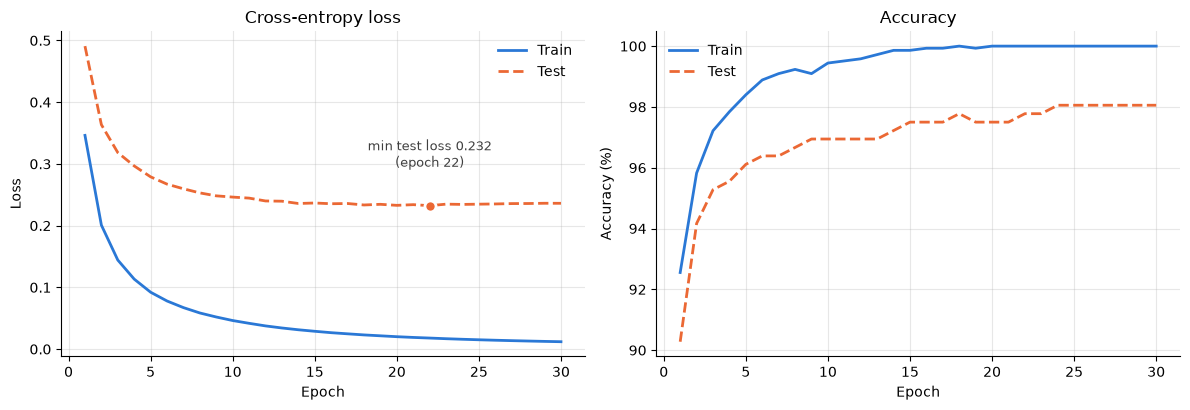

Train loss: 0.3462 -> 0.0120
Test loss:  0.4908 -> min 0.2323 at epoch 22 -> 0.2362 at the end

Curves plotted; both loss curves go down.


In [14]:
TRAIN_COLOR, TEST_COLOR = "#2a78d6", "#eb6834"   # blue / orange, a colorblind-safe pair


def plot_history(history):
    """Plot loss and accuracy per epoch for the train and test sets.

    Parameters
    ----------
    history : dict with lists train_loss, train_acc, test_loss, test_acc (one value per epoch)

    Returns
    -------
    None. Shows a figure with two side-by-side plots and marks the epoch of minimum test loss.
    """
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    best = int(np.argmin(history["test_loss"]))          # index of the lowest test loss

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, key, title, ylabel in [(ax_loss, "loss", "Cross-entropy loss", "Loss"),
                                   (ax_acc, "acc", "Accuracy", "Accuracy (%)")]:
        scale = 100 if key == "acc" else 1
        ax.plot(epochs, scale * np.array(history[f"train_{key}"]), color=TRAIN_COLOR, lw=2, label="Train")
        ax.plot(epochs, scale * np.array(history[f"test_{key}"]), color=TEST_COLOR, lw=2, ls="--", label="Test")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        ax.legend(frameon=False)

    ax_loss.plot(epochs[best], history["test_loss"][best], "o", color=TEST_COLOR, ms=8, mec="white", mew=2)
    ax_loss.annotate(f"min test loss {history['test_loss'][best]:.3f}\n(epoch {epochs[best]})",
                     (epochs[best], history["test_loss"][best]), textcoords="offset points",
                     xytext=(0, 28), ha="center", fontsize=9, color="0.25")
    plt.tight_layout()
    plt.show()


plot_history(history)

best_epoch = int(np.argmin(history["test_loss"])) + 1
print(f"Train loss: {history['train_loss'][0]:.4f} -> {history['train_loss'][-1]:.4f}")
print(f"Test loss:  {history['test_loss'][0]:.4f} -> min {min(history['test_loss']):.4f} at epoch {best_epoch} "
      f"-> {history['test_loss'][-1]:.4f} at the end")

# Check (task 5.2)
assert history["train_loss"][-1] < history["train_loss"][0], "Training loss curve does not go down"
assert history["test_loss"][-1] < history["test_loss"][0], "Test loss curve does not go down"
print("\nCurves plotted; both loss curves go down.")

### Prediction grid

`show_prediction_grid` shows the first 16 test images in a 4 × 4 grid, with the predicted and the true label above each one. Wrong predictions have a **red** title and a ✗, correct ones a dark title and a ✓, so mistakes are visible without relying on color.

The images are drawn from `X_test_raw`, the pixels **before** standardization (0–16), reshaped from 64 values back to 8 × 8. Standardized pixels would look distorted, because each pixel was rescaled by its own mean and std. The predictions themselves come from the standardized `X_test`, as during training.

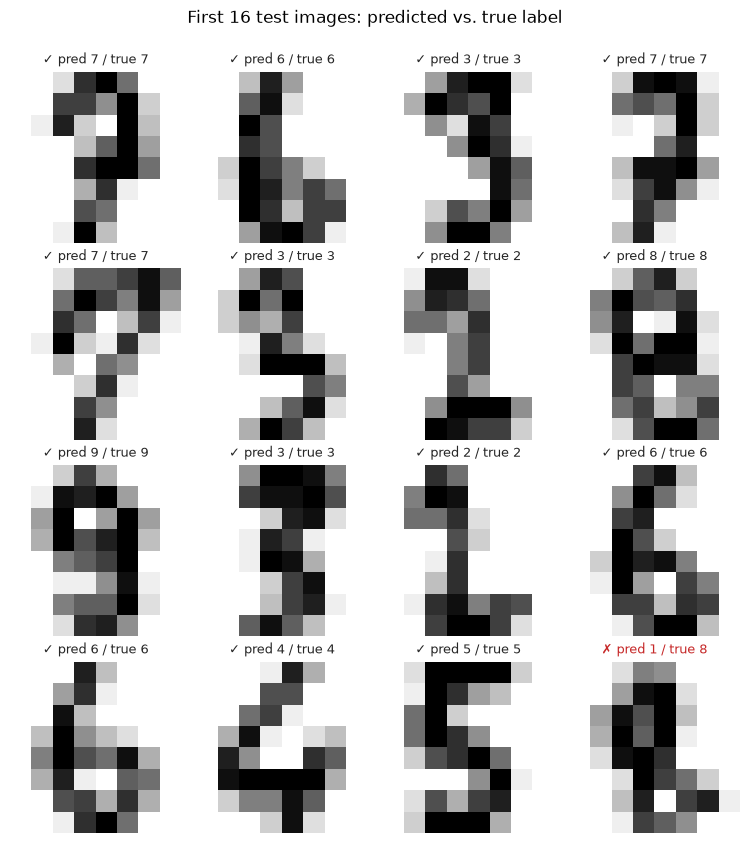

Wrong predictions among these 16 images: 1 (red titles: 1)
Prediction grid correct.


In [15]:
WRONG_COLOR = "#c62828"   # red, used only for wrong predictions


def show_prediction_grid(X_raw, y_true, y_pred, n=16):
    """Show the first n test images with their predicted and true labels.

    Parameters
    ----------
    X_raw : array, shape (N, 64), unstandardized pixels (0-16)
    y_true, y_pred : arrays of int, shape (N,)
    n : int, number of images (a perfect square, e.g. 16 for a 4 x 4 grid)

    Returns
    -------
    fig : the matplotlib figure. Titles of wrong predictions are red and marked with a cross.
    """
    side = int(np.sqrt(n))
    fig, axes = plt.subplots(side, side, figsize=(1.9 * side, 2.1 * side))
    for i, ax in enumerate(axes.ravel()):
        correct = y_pred[i] == y_true[i]
        ax.imshow(X_raw[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        ax.set_title(f"{'✓' if correct else '✗'} pred {y_pred[i]} / true {y_true[i]}",
                     fontsize=9, color="0.15" if correct else WRONG_COLOR)
        ax.axis("off")
    fig.suptitle(f"First {n} test images: predicted vs. true label", y=1.0)
    plt.tight_layout()
    plt.show()
    return fig


fig = show_prediction_grid(X_test_raw, y_test, y_test_pred)

n_wrong_shown = int(np.sum(y_test_pred[:16] != y_test[:16]))
n_red_titles = sum(ax.title.get_color() == WRONG_COLOR for ax in fig.axes)
print(f"Wrong predictions among these 16 images: {n_wrong_shown} (red titles: {n_red_titles})")

# Check (task 5.3)
assert len(fig.axes) == 16, "The grid should contain 16 images"
assert n_red_titles == n_wrong_shown, "Red titles do not match the wrong predictions"
print("Prediction grid correct.")

### Error analysis

The test accuracy is a single number; the **confusion matrix** shows *which* digits are confused with which. Entry $C_{ij}$ counts the test images of true class $i$ predicted as class $j$:

- the **diagonal** holds the correct predictions; everything off the diagonal is a mistake;
- each **row** sums to the number of test images of that class, so the **per-class accuracy** (recall) is $C_{ii} / \sum_j C_{ij}$;
- the trace divided by 360 is the overall test accuracy.

`confusion_matrix` builds it with `np.add.at`, which adds 1 at position `(true, predicted)` for every image (it handles repeated positions correctly, unlike `C[y_true, y_pred] += 1`). The cell also lists the most confused pairs and how confident the network was on its mistakes, using `predict_proba`.

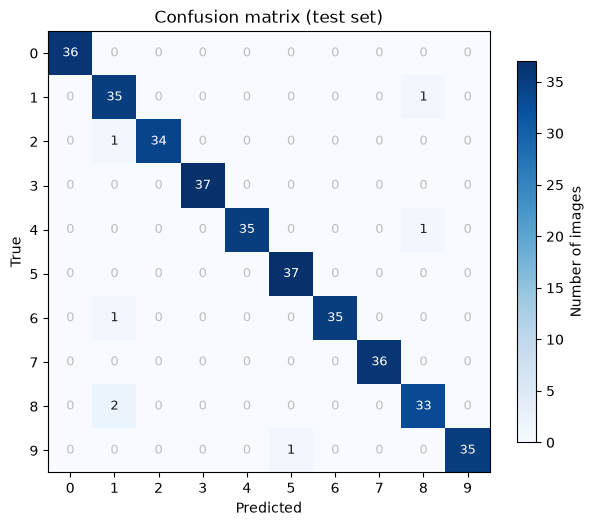

Per-class accuracy:
  digit 0: 100.0 %  (36/36)
  digit 1:  97.2 %  (35/36)
  digit 2:  97.1 %  (34/35)
  digit 3: 100.0 %  (37/37)
  digit 4:  97.2 %  (35/36)
  digit 5: 100.0 %  (37/37)
  digit 6:  97.2 %  (35/36)
  digit 7: 100.0 %  (36/36)
  digit 8:  94.3 %  (33/35)
  digit 9:  97.2 %  (35/36)

Mistakes (true -> predicted: count): 8->1: 2, 9->5: 1, 6->1: 1, 4->8: 1, 2->1: 1, 1->8: 1
Mean confidence (max probability): correct 0.975, wrong 0.927
Probability given to the true class on the mistakes: [0.047, 0.002, 0.0, 0.001, 0.083, 0.098, 0.004]

Confusion matrix consistent with the test accuracy.


In [16]:
def confusion_matrix(y_true, y_pred, num_classes=10):
    """Count predictions per (true class, predicted class) pair.

    Parameters
    ----------
    y_true, y_pred : arrays of int, shape (N,)
    num_classes : int

    Returns
    -------
    C : ndarray of int, shape (num_classes, num_classes); C[i, j] = number of
        images of class i predicted as class j.
    """
    C = np.zeros((num_classes, num_classes), dtype=int)
    np.add.at(C, (y_true, y_pred), 1)
    return C


def plot_confusion_matrix(C):
    """Show a confusion matrix as a heatmap with the count written in every cell.

    Parameters
    ----------
    C : ndarray of int, shape (K, K), rows = true class, columns = predicted class

    Returns
    -------
    None. Shows the figure.
    """
    K = C.shape[0]
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    image = ax.imshow(C, cmap="Blues")
    for i in range(K):
        for j in range(K):
            if C[i, j] == 0:
                color = "0.75"                                   # zeros recede
            else:
                color = "white" if C[i, j] > C.max() / 2 else "0.1"
            ax.text(j, i, C[i, j], ha="center", va="center", fontsize=9, color=color)
    ax.set_xticks(range(K))
    ax.set_yticks(range(K))
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title("Confusion matrix (test set)")
    fig.colorbar(image, ax=ax, shrink=0.8, label="Number of images")
    plt.tight_layout()
    plt.show()


C = confusion_matrix(y_test, y_test_pred)
plot_confusion_matrix(C)

class_counts = C.sum(axis=1)
class_acc = np.diag(C) / class_counts
print("Per-class accuracy:")
for k in range(10):
    print(f"  digit {k}: {100 * class_acc[k]:5.1f} %  ({C[k, k]}/{class_counts[k]})")

off_diagonal = [(C[i, j], i, j) for i in range(10) for j in range(10) if i != j and C[i, j] > 0]
print("\nMistakes (true -> predicted: count):", ", ".join(f"{i}->{j}: {n}" for n, i, j in sorted(off_diagonal, reverse=True)))

probs_test = predict_proba(trained_params, X_test)
wrong = y_test_pred != y_test
print(f"Mean confidence (max probability): correct {probs_test[~wrong].max(axis=1).mean():.3f}, "
      f"wrong {probs_test[wrong].max(axis=1).mean():.3f}")
print(f"Probability given to the true class on the mistakes: {np.round(probs_test[wrong, y_test[wrong]], 3).tolist()}")

# Check (task 5.4)
assert C.shape == (10, 10) and C.sum() == len(y_test) == 360, "The matrix should count all 360 test images"
assert np.array_equal(class_counts, np.bincount(y_test, minlength=10)), "Each row must sum to that class's test count"
assert np.isclose(np.trace(C) / C.sum(), test_acc), "Trace / 360 must equal the test accuracy"
print("\nConfusion matrix consistent with the test accuracy.")

**Interpretation** (numbers from the run with `seed = 0`; they are printed above):

- **Few, scattered errors.** 7 of 360 test images are wrong (98.06 %). Four digits are perfect (0, 3, 5, 7: 100 %); every other class has one mistake (≈ 97 %), except 8.
- **The weakest class is 8** (94.3 %, 33 of 35): both of its mistakes are predicted as **1**.
- **The 1 ↔ 8 pair dominates.** It accounts for 3 of the 7 errors (8 → 1 twice, 1 → 8 once), and **1 is the most frequent wrong prediction** (4 of 7: from 8, 8, 6 and 2). At 8 × 8 resolution, a thin 8 whose loops collapse is a mostly vertical stroke, as is a 1; the 8 → 1 image in the prediction grid is an example.
- **The mistakes are confident.** On wrong images the network still gives its top class a mean probability of about 0.93 (0.84–0.99), and the true class at most 0.10. Cross-entropy charges $-\log p_{\text{true}}$, so these few confident mistakes are what keeps the **test loss** (0.236) far above the train loss (0.012), even though the accuracies are close.
- **Train–test gap.** 100 % train vs. 98.06 % test accuracy. The training loss keeps falling toward 0, while the test loss reaches its minimum at epoch 22 and then rises slightly: the network keeps becoming more confident, including on these 7 images. This is mild overfitting; it does not cost accuracy within 30 epochs, but it is what regularization or early stopping would address (out of scope, `spec.md` §2).

### Learning-rate experiment

The learning rate $\eta$ sets the size of every step $\theta \leftarrow \theta - \eta\,\nabla_\theta L$. To see its effect, a **new** network is trained for each of $\eta \in \{0.001, 0.01, 0.1, 1.0, 5.0\}$. Everything else is copied from `CONFIG` (architecture, seeds, so the same initial weights and the same batch order, batch size, epochs), so **the learning rate is the only difference** between runs.

- `run_lr_experiment` trains each network with `train(..., verbose=False)`. A run whose loss becomes `NaN`/`Inf` raises the `ValueError` of FR5.4; here that outcome is *expected*, so it is caught and recorded as "diverged" instead of stopping the notebook. NumPy's overflow warnings, which are the expected symptom of a too-large step, are silenced **only inside this experiment** with `np.errstate`.
- `plot_lr_experiment` prints a summary table and plots the training-loss curves of the completed runs on a **logarithmic** y-axis, because the losses span several orders of magnitude.

This experiment is **illustrative**: the configured learning rate (0.1) is not changed based on these test accuracies (`spec.md` §2). The main model trained in section 4 is not touched.

learning rate  final train loss  test accuracy
        0.001            0.9172         80.28 %
         0.01            0.1464         95.28 %
          0.1            0.0120         98.06 %
          1.0            0.0004         97.50 %
          5.0       diverged: epoch 8, batch 31


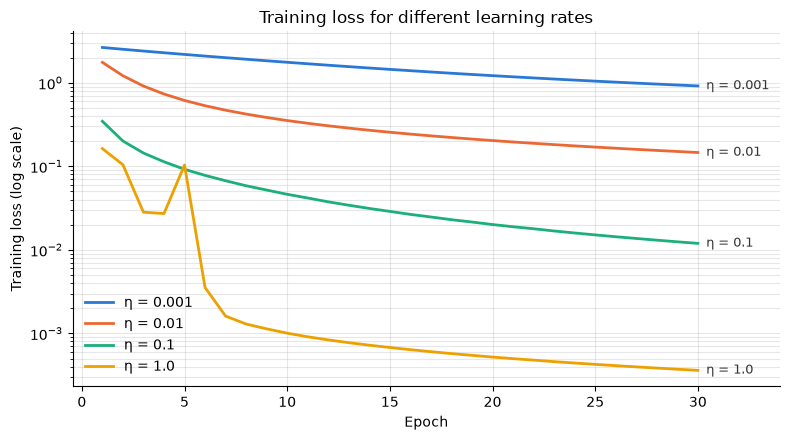


Main model unchanged (test accuracy 98.06 %).


In [17]:
LR_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order, one per rate


def run_lr_experiment(learning_rates, X_train, Y_train, X_test, Y_test, config):
    """Train a new network for each learning rate, all other settings from config.

    Parameters
    ----------
    learning_rates : list of float
    X_train, Y_train, X_test, Y_test : the prepared data (as for train)
    config : dict, the base configuration (not modified)

    Returns
    -------
    results : dict {lr: {"history": dict, "test_acc": float}} for completed runs,
              or {lr: {"diverged": str}} with the error message for runs that diverged.
    """
    results = {}
    # Overflow is the expected behaviour of a too-large learning rate here, so its warnings are silenced
    # only inside this block; the divergence itself is still detected and reported by train().
    with np.errstate(over="ignore", invalid="ignore"):
        for lr in learning_rates:
            run_config = dict(config, learning_rate=lr)                       # copy; only the rate changes
            initial = init_params(run_config["layer_sizes"], np.random.default_rng(run_config["seed"]))
            try:
                run_params, run_history = train(initial, X_train, Y_train, X_test, Y_test, run_config, verbose=False)
                results[lr] = {"history": run_history, "test_acc": run_history["test_acc"][-1]}
            except ValueError as error:
                results[lr] = {"diverged": str(error)}
    return results


def plot_lr_experiment(results):
    """Print a summary table and plot the training-loss curves of the completed runs.

    Parameters
    ----------
    results : dict returned by run_lr_experiment

    Returns
    -------
    None. Prints the table and shows one plot (log-scale y-axis), with a legend and a label at the end of each curve.
    """
    print(f"{'learning rate':>13}  {'final train loss':>16}  {'test accuracy':>13}")
    for lr, result in results.items():
        if "diverged" in result:
            print(f"{lr:>13}  {'diverged: ' + result['diverged'].split(':')[0].replace('Training stopped at ', ''):>32}")
        else:
            print(f"{lr:>13}  {result['history']['train_loss'][-1]:>16.4f}  {100 * result['test_acc']:>12.2f} %")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for (lr, result), color in zip(results.items(), LR_COLORS):
        if "diverged" in result:
            continue
        losses = result["history"]["train_loss"]
        epochs = np.arange(1, len(losses) + 1)
        ax.plot(epochs, losses, color=color, lw=2, label=f"η = {lr}")
        ax.annotate(f"η = {lr}", (epochs[-1], losses[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color="0.2")
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss (log scale)")
    ax.set_title("Training loss for different learning rates")
    ax.grid(alpha=0.3, which="both")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="lower left")
    ax.set_xlim(right=len(epochs) + 4)                               # room for the end labels
    plt.tight_layout()
    plt.show()


test_acc_before = accuracy(trained_params, X_test, y_test)
lr_results = run_lr_experiment([0.001, 0.01, 0.1, 1.0, 5.0], X_train, Y_train, X_test, Y_test, CONFIG)
plot_lr_experiment(lr_results)
test_acc_after = accuracy(trained_params, X_test, y_test)

# Check (task 5.5)
assert list(lr_results) == [0.001, 0.01, 0.1, 1.0, 5.0], "There should be one result per learning rate"
assert np.isclose(lr_results[0.1]["test_acc"], test_acc), "The 0.1 run should reproduce the main model (same seeds)"
assert test_acc_after == test_acc_before == test_acc, "The main model must not be modified by the experiment"
assert CONFIG["learning_rate"] == 0.1, "The configured learning rate must not change"
print(f"\nMain model unchanged (test accuracy {100 * test_acc_after:.2f} %).")

**Interpretation** (numbers from the run with `seed = 0`; they are printed above):

- **Too small (η = 0.001):** every step is tiny, so after 30 epochs the training loss is still 0.92 and the test accuracy only 80.3 %. The curve is still falling: the network is not wrong, just far from finished (underfitting by lack of training).
- **Small (η = 0.01):** the same pattern, ten times faster: loss 0.146, test accuracy 95.3 %. Still clearly improving at epoch 30.
- **Good (η = 0.1, the configured value):** a smooth curve that reaches a training loss of 0.012 and 98.06 % test accuracy. It reproduces the main model exactly, because the seeds are the same.
- **Large (η = 1.0):** the training loss falls fastest and lowest (0.0004), but the curve is **unstable**: it jumps from about 0.03 back up to 0.10 at epoch 5 when a step overshoots, before settling. Its test accuracy (97.5 %) is two images below η = 0.1, a difference within the noise of a 360-image test set; the much lower training loss mostly means the network has become even more confident on the training set.
- **Too large (η = 5.0):** each step overshoots so far that the weights grow until the logits overflow; the loss becomes `NaN` at epoch 8, batch 31, and training stops with the FR5.4 message.

So a learning rate that is too small wastes epochs, and one that is too large makes training unstable or makes it diverge. 0.1 is in the range where training is both fast and stable. It was chosen from this training behaviour, not from the test accuracies in the table.

## 6. Robustness

Trigger every invalid-input case and show that each one produces a clear error message (`spec.md` FR7).

### Error handling

Every function checks its inputs where it receives them (`architecture.md` §4.6) and raises a `ValueError` whose message says **what** is wrong, **where**, and the **expected vs. received** value. Without these checks, most of these mistakes would end in a cryptic NumPy error (e.g. `shapes (5,63) and (64,64) not aligned`), or worse, would not fail at all: a label of −1 would silently become class 9.

`expect_error` calls a function with deliberately invalid input, catches the `ValueError` and prints its message. Each line below triggers one case of the `spec.md` FR7 table. Every call uses copies or slices, so nothing computed earlier in the notebook is modified.

In [18]:
def expect_error(description, function, *args):
    """Call function(*args), expecting a ValueError, and print its message.

    Parameters
    ----------
    description : str, the case being tested
    function : callable; *args : its arguments

    Returns
    -------
    bool: True if a ValueError was raised, False otherwise (a warning is printed).
    """
    try:
        function(*args)
    except ValueError as error:
        print(f"{description:<34} -> {error}")
        return True
    print(f"{description:<34} -> WARNING: no error was raised")
    return False


broken_params = [trained_params[0], (np.zeros((32, 10)), np.zeros(10))]   # layer 2 expects 32 inputs, layer 1 gives 64

with np.errstate(over="ignore", invalid="ignore"):   # the diverging run overflows on purpose
    raised = [
        expect_error("Input features != first layer", forward, trained_params, X_test[:5, :63]),
        expect_error("Incompatible consecutive layers", forward, broken_params, X_test[:5]),
        expect_error("Invalid layer sizes", init_params, [64], np.random.default_rng(0)),
        expect_error("Empty mini-batch", check_batch, X_train[:0], Y_train[:0]),
        expect_error("X and Y row counts differ", check_batch, X_train[:32], Y_train[:31]),
        expect_error("Label out of range", one_hot, np.array([3, 7, 12])),
        expect_error("Invalid hyperparameter", validate_config, dict(CONFIG, learning_rate=-0.1)),
        expect_error("Loss becomes NaN during training", train, params, X_train, Y_train, X_test, Y_test,
                     dict(CONFIG, learning_rate=5.0), False),
    ]

# Check (task 6.1)
assert len(raised) == 8 and all(raised), "Every invalid input must raise a ValueError"
assert accuracy(trained_params, X_test, y_test) == test_acc, "The error cases must not modify the trained model"
print(f"\nAll {len(raised)} invalid inputs produced a clear error; the notebook keeps running.")

Input features != first layer      -> Input has 63 features, but the first layer expects 64.
Incompatible consecutive layers    -> Layer 2 weight has 32 input rows, but layer 1 outputs 64 values.
Invalid layer sizes                -> Layer sizes must be at least [input, output] with positive integers, got [64].
Empty mini-batch                   -> Empty mini-batch: received 0 samples.
X and Y row counts differ          -> X has 32 rows but Y has 31 rows.
Label out of range                 -> Label 12 at index 2 is out of range; labels must be integers in 0-9.
Invalid hyperparameter             -> Learning rate must be > 0, got -0.1.
Loss becomes NaN during training   -> Training stopped at epoch 8, batch 31: the loss is nan. Try a lower learning rate.

All 8 invalid inputs produced a clear error; the notebook keeps running.
